# STL Equivalence Checking Pipeline

This notebook documents the equivalence checking pipeline for the ATIC NL-STL project.

## Architecture

```
manual_review_mapping.csv
         │
         ▼
scale_bound_norm.py  ──→  data/layer1.csv  (suitability: stlsat | spot | skip)
         │
         ▼
STL_LTL_translation.py  ──→  data/layer2.csv  (+ ltl_gold, ltl_pred columns)
         │
         ├──→  spot_checker.py   ──→  data/spot_results.csv
         └──→  stlsat_checker.py ──→  data/stlsat_results.csv
```

## Routing logic
- `stlsat`: bounded operators, integer intervals → STLSat exact check
- `spot`: unbounded G/F (bounded with horizon for SPOT) → LTL translation → SPOT
- `skip`: contains `rise()` or other unsupported operators


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import subprocess
from pathlib import Path

# ensure data dir exists
Path('data').mkdir(exist_ok=True)

## Step 1 — Layer 1: Scale & Bound Normalisation

In [ ]:
result = subprocess.run(
    ['python', 'scale_bound_norm.py',
     '--input',  '../ATIC_ManualReview/manual_review_mapping.csv',
     '--output', 'data/layer1.csv'],
    capture_output=True, text=True
)
print(result.stdout)
if result.returncode != 0:
    print('STDERR:', result.stderr)

Processing 151 pairs …

  [P] MR-001      → spot
  [S] MR-002      → stlsat
  [-] MR-003      → skip
  [-] MR-003      → skip
  [-] MR-003      → skip
  [S] MR-004      → stlsat
  [S] MR-004      → stlsat
  [S] MR-004      → stlsat
  [S] MR-005      → stlsat
  [P] MR-006      → spot
  [S] MR-007      → stlsat
  [-] MR-008      → skip
  [-] MR-009      → skip
  [-] MR-009      → skip
  [-] MR-010      → skip
  [-] MR-010      → skip
  [-] MR-010      → skip
  [-] MR-011      → skip
  [-] MR-012      → skip
  [-] MR-013      → skip
  [-] MR-013      → skip
  [P] MR-014      → spot
  [P] MR-015      → spot
  [P] MR-016      → spot
  [-] MR-017      → skip
  [-] MR-018      → skip
  [-] MR-018      → skip
  [S] MR-019      → stlsat
  [P] MR-020      → spot
  [P] MR-021      → spot
  [S] MR-022      → stlsat
  [S] MR-023      → stlsat
  [-] MR-024      → skip
  [-] MR-025      → skip
  [-] MR-026      → skip
  [P] MR-027      → spot
  [P] MR-027      → spot
  [P] MR-028      → spot
  [P] MR

In [ ]:
layer1 = pd.read_csv('data/layer1.csv')
print(f'Layer 1: {len(layer1)} rows')
layer1['suitability'].value_counts()

Layer 1: 151 rows


suitability
spot      79
skip      37
stlsat    35
Name: count, dtype: int64

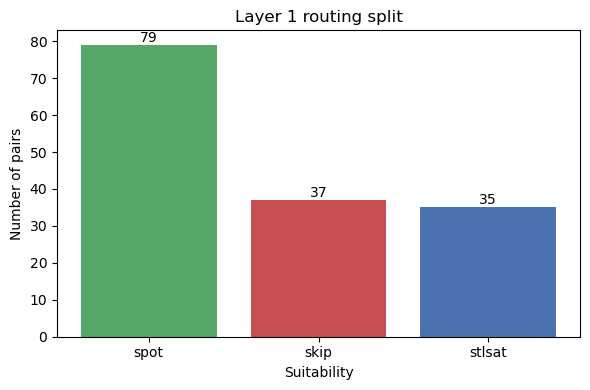

In [ ]:
# visualise routing split
counts = layer1['suitability'].value_counts()
colors = {'stlsat': '#4C72B0', 'spot': '#55A868', 'skip': '#C44E52'}

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values,
              color=[colors.get(k, 'grey') for k in counts.index])
ax.bar_label(bars, fmt='%d')
ax.set_title('Layer 1 routing split')
ax.set_ylabel('Number of pairs')
ax.set_xlabel('Suitability')
plt.tight_layout()
plt.show()

In [ ]:
# inspect skipped pairs
skipped = layer1[layer1['suitability'] == 'skip']
print(f'Skipped pairs: {len(skipped)}')
skipped[['review_id', 'gold_formula', 'predicted_formula', 'warnings']].head(10)

Skipped pairs: 37


,review_id,gold_formula,predicted_formula,warnings
2,MR-003,"G(rise(fault = 1) -> F[0,5](G[0,10](recovery =...","G(rise(fault) -> F[0,5](rise(recovery) & G[0,1...",Contains rise() — unsupported by STLSat and SP...
3,MR-003,"G(rise(fault = 1) -> F[0,5](G[0,10](recovery =...","G(rise(fault) -> F[0,5](rise(recovery) & G[0,1...",Contains rise() — unsupported by STLSat and SP...
4,MR-003,"G(rise(fault = 1) -> F[0,5](G[0,10](recovery =...","G(rise(fault) -> F[0,5](rise(recovery) & G[0,1...",Contains rise() — unsupported by STLSat and SP...
11,MR-008,"G(rise(enable = 1) -> F[0,1](output = 1)) & G(...","G((rise(enable = 1)) -> F[0,1](rise(output = 1...",Contains rise() — unsupported by STLSat and SP...
12,MR-009,"G(rise(enable = 1) -> F[0,1](output = 1)) & G(...","G(rise(enable) -> F[0,1](output = 1)) & G(fall...",Contains rise() — unsupported by STLSat and SP...
13,MR-009,"G(rise(enable = 1) -> F[0,1](output = 1)) & G(...","G(rise(enable) -> F[0,1](output = 1)) & G(fall...",Contains rise() — unsupported by STLSat and SP...
14,MR-010,"G(rise(A = 1) -> G[0,20](B < 3))","G(rise(A) -> G[0,20](B < 3))",Contains rise() — unsupported by STLSat and SP...
15,MR-010,"G(rise(A = 1) -> G[0,20](B < 3))","G(rise(A) -> G[0,20](B < 3))",Contains rise() — unsupported by STLSat and SP...
16,MR-010,"G(rise(A = 1) -> G[0,20](B < 3))","G(rise(A) -> G[0,20](B < 3))",Contains rise() — unsupported by STLSat and SP...
17,MR-011,"G(rise(request = 1) -> F[0,3](grant = 1))","G((rise(request)) -> (F[0,3](grant)))",Contains rise() — unsupported by STLSat and SP...


## Step 2 — Layer 2: STL → LTL Translation

In [ ]:
result = subprocess.run(
    ['python', 'STL_LTL_translation.py',
     '--input',  'data/layer1.csv',
     '--output', 'data/layer2.csv'],
    capture_output=True, text=True
)
print(result.stdout[-2000:])  # tail of output
if result.returncode != 0:
    print('STDERR:', result.stderr)

_event -> (in_guard_region U release_event))

  MR-102    
    STL gold : G[0,100](guard_event -> ((in_guard_region = 1) U[0,120] release_event))
    LTL gold : G(guard_event -> ((in_guard_region) U release_event))
    STL pred : G[0,100](guard_event -> (in_guard_region U[0,120] release_event))
    LTL pred : G(guard_event -> (in_guard_region U release_event))

  MR-103    
    STL gold : G[0,100](inspection_event -> (F[0,20](in_A_r1) & F[0,25](in_B_r2)))
    LTL gold : G(inspection_event -> (F(in_A_r1) & F(in_B_r2)))
    STL pred : G[0,100]((inspection_event = 1) -> (F[0,20](in_A_r1 = 1) & F[0,25](in_B_r2 = 1)))
    LTL pred : G((inspection_event) -> (F(in_A_r1) & F(in_B_r2)))

  MR-108    
    STL gold : G[0,100](insertion_phase -> (contact_force < 20))
    LTL gold : G(insertion_phase -> (contact_force_lt_20))
    STL pred : G[0,100]((insertion_phase = 1) -> (contact_force < 20))
    LTL pred : G((insertion_phase) -> (contact_force_lt_20))

  MR-108    
    STL gold : G[0,100](inser

In [ ]:
layer2 = pd.read_csv('data/layer2.csv')
# show a sample of spot translations
spot_rows = layer2[layer2['suitability'] == 'spot']
spot_rows[['review_id', 'gold_normalised', 'ltl_gold', 'pred_normalised', 'ltl_pred']].head(10)

,review_id,gold_normalised,ltl_gold,pred_normalised,ltl_pred
0,MR-001,"G[0,100]((pump_primary = 1) | (pump_secondary ...",G((pump_primary) | (pump_secondary) | (pump_em...,"G[0,100](pump_primary | pump_secondary | pump_...",G(pump_primary | pump_secondary | pump_emergency)
9,MR-006,"G[0,100]((reset = 1) -> H[0,5](fault = 0))","G((reset) -> H[0,5](!fault))","G[0,100](reset -> H[0,5](!fault))","G(reset -> H[0,5](!fault))"
21,MR-014,"G[0,100]((primary_ok = 0) -> (backup_active = 1))",G((!primary_ok) -> (backup_active)),"G[0,100]((primary_ok = 0) -> (backup_active = 1))",G((!primary_ok) -> (backup_active))
22,MR-015,"G[0,100]((primary_ok = 0) -> (backup_active = 1))",G((!primary_ok) -> (backup_active)),"G[0,100]((primary_ok = 0) -> F[0,100](backup_a...",G((!primary_ok) -> F(backup_active))
23,MR-016,"G[0,100]((primary_ok = 0) -> (backup_active = 1))",G((!primary_ok) -> (backup_active)),"G[0,100]((primary_ok = 0) -> backup_active)",G((!primary_ok) -> backup_active)
28,MR-020,"G[0,100]((!((temperature >= 20) & (temperature...",G((!((temperature_ge_20) & (temperature_le_30)...,"G[0,100]((temperature < 20 | temperature > 30)...",G((temperature_lt_20 | temperature_gt_30) -> F...
29,MR-021,"(F[0,90](goal_1_r1 | goal_1_r2 | goal_1_r3) & ...",(F(goal_1_r1 | goal_1_r2 | goal_1_r3) & F(goal...,"(F[0,90](goal_1_r1 = 1 | goal_1_r2 = 1 | goal_...",(F(goal_1_r1 | goal_1_r2 | goal_1_r3) & F(goal...
35,MR-027,"G[0,100]((grant = 1) -> O[0,5](request = 1))","G((grant) -> O[0,5](request))","G[0,100](grant -> O[0,5](request))","G(grant -> O[0,5](request))"
36,MR-027,"G[0,100]((grant = 1) -> O[0,5](request = 1))","G((grant) -> O[0,5](request))","G[0,100](grant -> O[0,5](request))","G(grant -> O[0,5](request))"
37,MR-028,"G[0,100](((A = 1) | ((B = 1) & (C = 0))) -> F[...",G(((A) | ((B) & (!C))) -> F(D)),"G[0,100](((A | B) & !C) -> F[0,2](D))",G(((A | B) & !C) -> F(D))


## Step 3a — SPOT Equivalence Check

In [ ]:
result = subprocess.run(
    ['python', 'spot_checker.py',
     '--input',  'data/layer2.csv',
     '--output', 'data/spot_results.csv'],
    capture_output=True, text=True
)
print(result.stdout)
if result.returncode != 0:
    print('STDERR:', result.stderr)

Checking 79 SPOT pairs from layer2.csv …
(Passing through 72 non-spot rows unchanged)

  [✓] MR-001      EQUIVALENT
  [!] MR-006      ERROR
  [✓] MR-014      EQUIVALENT
  [✗] MR-015      NON_EQUIVALENT
  [✓] MR-016      EQUIVALENT
  [✗] MR-020      NON_EQUIVALENT
  [✓] MR-021      EQUIVALENT
  [!] MR-027      ERROR
  [!] MR-027      ERROR
  [✗] MR-028      NON_EQUIVALENT
  [✗] MR-028      NON_EQUIVALENT
  [✓] MR-032      EQUIVALENT
  [✓] MR-032      EQUIVALENT
  [✓] MR-034      EQUIVALENT
  [✓] MR-035      EQUIVALENT
  [✓] MR-036      EQUIVALENT
  [✓] MR-040      EQUIVALENT
  [✓] MR-040      EQUIVALENT
  [✗] MR-041      NON_EQUIVALENT
  [✗] MR-042      NON_EQUIVALENT
  [✗] MR-043      NON_EQUIVALENT
  [✗] MR-044      NON_EQUIVALENT
  [✓] MR-045      EQUIVALENT
  [✓] MR-045      EQUIVALENT
  [✓] MR-046      EQUIVALENT
  [✓] MR-047      EQUIVALENT
  [✓] MR-047      EQUIVALENT
  [!] MR-048      ERROR
  [✓] MR-049      EQUIVALENT
  [✓] MR-050      EQUIVALENT
  [✗] MR-051      NON_EQUIVALEN

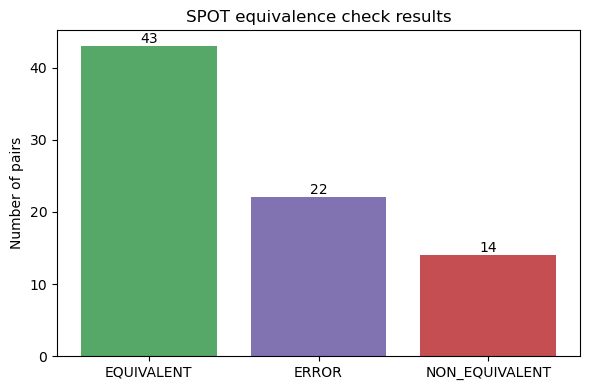

In [ ]:
spot_results = pd.read_csv('data/spot_results.csv')
spot_only = spot_results[spot_results['suitability'] == 'spot']

counts = spot_only['equiv_verdict'].value_counts()
colors = {'EQUIVALENT': '#55A868', 'NON_EQUIVALENT': '#C44E52', 'ERROR': '#8172B2'}

fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(counts.index, counts.values,
              color=[colors.get(k, 'grey') for k in counts.index])
ax.bar_label(bars, fmt='%d')
ax.set_title('SPOT equivalence check results')
ax.set_ylabel('Number of pairs')
plt.tight_layout()
plt.show()

In [ ]:
# inspect equivalent pairs
equiv = spot_only[spot_only['equiv_verdict'] == 'EQUIVALENT']
print(f'Equivalent pairs found by SPOT: {len(equiv)}')
equiv[['review_id', 'gold_formula', 'predicted_formula']].to_string(index=False)

Equivalent pairs found by SPOT: 43


'review_id                                                                                                                        gold_formula                                                                                                                                     predicted_formula\n   MR-001                                                                 G((pump_primary = 1) | (pump_secondary = 1) | (pump_emergency = 1))                                                                                                     G(pump_primary | pump_secondary | pump_emergency)\n   MR-014                                                                                          G((primary_ok = 0) -> (backup_active = 1))                                                                                                            G((primary_ok = 0) -> (backup_active = 1))\n   MR-016                                                                                          G((primary_ok = 0) ->

In [ ]:
# inspect errors — what is SPOT failing on?
errors = spot_only[spot_only['equiv_verdict'] == 'ERROR']
print(f'Errors: {len(errors)}')
errors[['review_id', 'ltl_gold', 'ltl_pred', 'equiv_detail']].head(10)

Errors: 22


,review_id,ltl_gold,ltl_pred,equiv_detail
1,MR-006,"G((reset) -> H[0,5](!fault))","G(reset -> H[0,5](!fault))","SPOT parse error: in method 'are_equivalent', ..."
7,MR-027,"G((grant) -> O[0,5](request))","G(grant -> O[0,5](request))","SPOT parse error: in method 'are_equivalent', ..."
8,MR-027,"G((grant) -> O[0,5](request))","G(grant -> O[0,5](request))","SPOT parse error: in method 'are_equivalent', ..."
27,MR-048,"G(u_turn_started -> H[0,4]((left_clear) & (rig...","G(u_turn_started -> H[0,4](left_clear & right_...","SPOT parse error: in method 'are_equivalent', ..."
35,MR-054,G(yielding -> ((accel_ge_m2) & (accel_le_1p5) ...,G(yielding -> ((accel_ge_m2) & (accel_le_1p5) ...,"SPOT parse error: in method 'are_equivalent', ..."
36,MR-055,G(yielding -> ((accel_ge_m2) & (accel_le_1p5) ...,G(yielding -> (accel_ge_m2 & accel_le_1p5 & ab...,"SPOT parse error: in method 'are_equivalent', ..."
37,MR-056,G(yielding -> ((accel_ge_m2) & (accel_le_1p5) ...,G(yielding -> (accel_ge_m2 & accel_le_1p5 & je...,"SPOT parse error: in method 'are_equivalent', ..."
38,MR-057,"G(enter_intersection -> H[0,2](light_green))","G(enter_intersection -> H[0,2](light_green))","SPOT parse error: in method 'are_equivalent', ..."
45,MR-071,G(approach -> ((abs(jerk) < 1) & (distance_lt_...,G((approach) & (abs(jerk) < 1) & (distance_lt_2)),"SPOT parse error: in method 'are_equivalent', ..."
46,MR-072,G(approach -> ((abs(jerk) < 1) & (distance_lt_...,G((approach) -> ((abs(jerk) < 1) & (distance_l...,"SPOT parse error: in method 'are_equivalent', ..."


## Step 3b — STLSat Equivalence Check

# TODO: add STLSAT checker that does not just process examples but works on dataset

In [ ]:
# TODO!

## Combined Results Summary

In [ ]:
# once both checkers have run, combine results here
# spot_results already has all rows; stlsat_results will add verdicts for stlsat rows

spot_results = pd.read_csv('data/spot_results.csv')

total = len(spot_results)
spot_eq  = len(spot_results[(spot_results['suitability']=='spot') & (spot_results['equiv_verdict']=='EQUIVALENT')])
spot_neq = len(spot_results[(spot_results['suitability']=='spot') & (spot_results['equiv_verdict']=='NON_EQUIVALENT')])
spot_err = len(spot_results[(spot_results['suitability']=='spot') & (spot_results['equiv_verdict']=='ERROR')])
n_skip   = len(spot_results[spot_results['suitability']=='skip'])
n_stlsat = len(spot_results[spot_results['suitability']=='stlsat'])

print(f'Total pairs     : {total}')
print(f'SPOT EQUIVALENT : {spot_eq}')
print(f'SPOT NON-EQUIV  : {spot_neq}')
print(f'SPOT ERROR      : {spot_err}')
print(f'STLSat (pending): {n_stlsat}')
print(f'Skipped (rise()): {n_skip}')